# 02 · Sudoku and All-Different

Constraint satisfaction at its cleanest. A Sudoku is nothing but **all-different** on every row, every column, and every box. We declare that, solve instantly, then meet two deeper ideas: proving a board has a **unique** solution, and proving an over-specified board is **infeasible**.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from repo root or notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt

from src.persistence import save_figure, save_json

print("figures ->", save_figure.__module__, "| ready")

figures -> src.persistence | ready


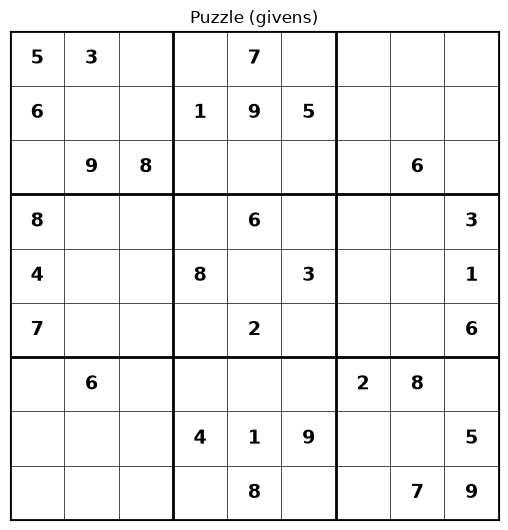

In [2]:
from src.datasets import instances
from src.evaluation.correctness import sudoku_violations, verify_sudoku
from src.models.sudoku import count_solutions, has_unique_solution, solve_sudoku
from src.visualisation import sudoku_figure

board = instances.valid_sudoku()
save_json("02_sudoku_puzzle", {"board": board})
fig = sudoku_figure(board, givens=board, title="Puzzle (givens)")
save_figure("02_sudoku_puzzle", fig)
plt.show()

## Declare the rules, fill the board
`solve_sudoku` builds integer variables 1..9 for every cell and adds one `add_all_different` per row, column, and box. That is the entire model.

status=OPTIMAL time=0.007s branches=0
all rules hold in the solution: True
violations: []


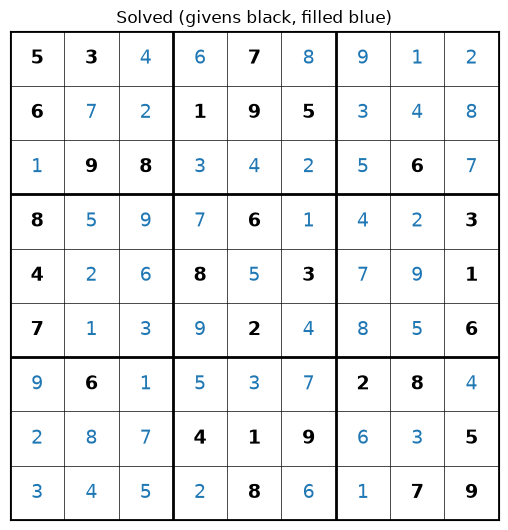

In [3]:
result = solve_sudoku(board, time_limit=10.0)
print(result.stats.summary())
assert result.solved is not None
print("all rules hold in the solution:", verify_sudoku(board, result.solved))
print("violations:", sudoku_violations(board, result.solved))
save_json("02_sudoku_solution", {"solution": result.solved, "status": result.stats.status_name})
fig = sudoku_figure(result.solved, givens=board, title="Solved (givens black, filled blue)")
save_figure("02_sudoku_solved", fig)
plt.show()

## Feasibility vs uniqueness
Finding *a* solution is feasibility. Proving it is the *only* solution is a second question: enumerate solutions, stop at two. A well-posed puzzle has exactly one.

In [4]:
print("solutions found (capped at 2):", count_solutions(board, limit=2, time_limit=10.0))
print("unique solution:", has_unique_solution(board, time_limit=10.0))

solutions found (capped at 2): 1
unique solution: True


## When the rules conflict: infeasibility
This board has two 5s in the first row. No completion can satisfy all-different, and the solver **proves** it — it does not loop or guess.

In [5]:
bad = instances.unsolvable_sudoku()
save_json("02_sudoku_unsolvable", {"board": bad})
bad_result = solve_sudoku(bad, time_limit=10.0)
print("status:", bad_result.stats.status_name)
print("infeasible proven:", bad_result.stats.is_infeasible, "| solved:", bad_result.solved)

status: INFEASIBLE
infeasible proven: True | solved: None


`all-different` is a **global constraint**: a first-class building block the solver reasons about efficiently, not a hand-rolled pile of pairwise `!=` inequalities. The rest of the project is the same idea with `no-overlap`, `at-most-one`, and friends.